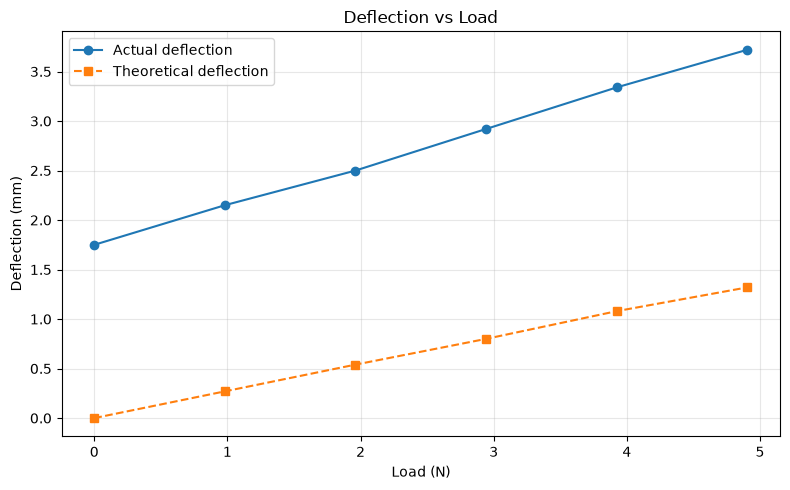

In [18]:
# experiment 1 for mechanics of structures 
import matplotlib.pyplot as plt

g = 9.81  # m/s^2

mass_g = [0, 100, 200, 300, 400, 500]
actual = [1.75, 2.15, 2.50, 2.92, 3.34, 3.72]       # mm
theoretical = [0, 0.27, 0.54, 0.80, 1.08, 1.32]     # mm

# Convert mass (g) to load/weight (N): W = m * g
load_N = [m / 1000 * g for m in mass_g]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(load_N, actual, "o-", label="Actual deflection")
ax.plot(load_N, theoretical, "s--", label="Theoretical deflection")

ax.set_xlabel("Load (N)")
ax.set_ylabel("Deflection (mm)")
ax.set_title("Deflection vs Load")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("deflection_vs_load.png", dpi=300)
plt.show()

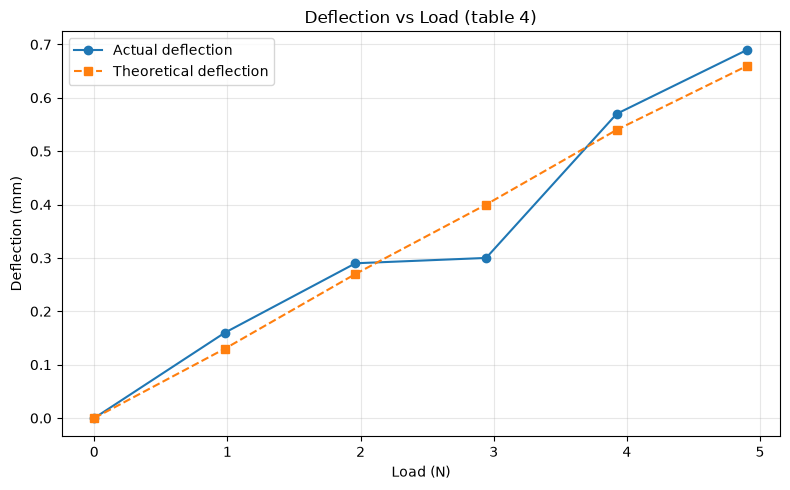

In [7]:
# experiment 2 for mechanics of structures (table 4)
import matplotlib.pyplot as plt

g = 9.81  # m/s^2

mass_g = [0, 100, 200, 300, 400, 500]
actual = [0, 0.16, 0.29, 0.3, 0.57, 0.69]       # mm
theoretical = [0, 0.13, 0.27, 0.4, 0.54, 0.66]     # mm

# Convert mass (g) to load/weight (N): W = m * g
load_N = [m / 1000 * g for m in mass_g]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(load_N, actual, "o-", label="Actual deflection")
ax.plot(load_N, theoretical, "s--", label="Theoretical deflection")

ax.set_xlabel("Load (N)")
ax.set_ylabel("Deflection (mm)")
ax.set_title("Deflection vs Load (table 4)")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("deflection_vs_load.png", dpi=300)
plt.show()

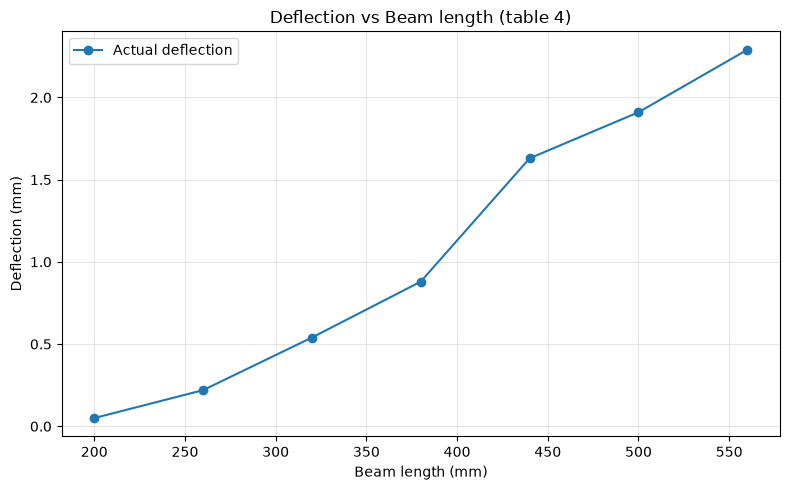

In [9]:
# experiment 2 for mechanics of structures (table 5)
import matplotlib.pyplot as plt

g = 9.81  # m/s^2

beam_legnth = [200, 260 ,320, 380, 440, 500, 560]
actual = [0.05, 0.22, 0.54, 0.88, 1.63, 1.91, 2.29]       # mm

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(beam_legnth, actual, "o-", label="Actual deflection")

ax.set_xlabel("Beam length (mm)")
ax.set_ylabel("Deflection (mm)")
ax.set_title("Deflection vs Beam length (table 4)")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("deflection_vs_load.png", dpi=300)
plt.show()

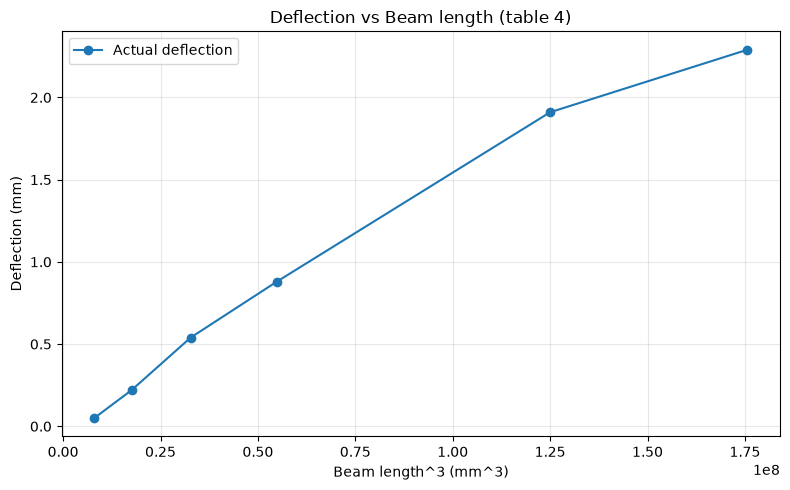

In [13]:
# experiment 2 for mechanics of structures (table 5, L^3)
import matplotlib.pyplot as plt

g = 9.81  # m/s^2

beam_legnth = [200**3, 260**3 ,320**3, 380**3, 500**3, 560**3]
actual = [0.05, 0.22, 0.54, 0.88, 1.91, 2.29]       # mm

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(beam_legnth, actual, "o-", label="Actual deflection")

ax.set_xlabel("Beam length^3 (mm^3)")
ax.set_ylabel("Deflection (mm)")
ax.set_title("Deflection vs Beam length (table 4)")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("deflection_vs_load.png", dpi=300)
plt.show()

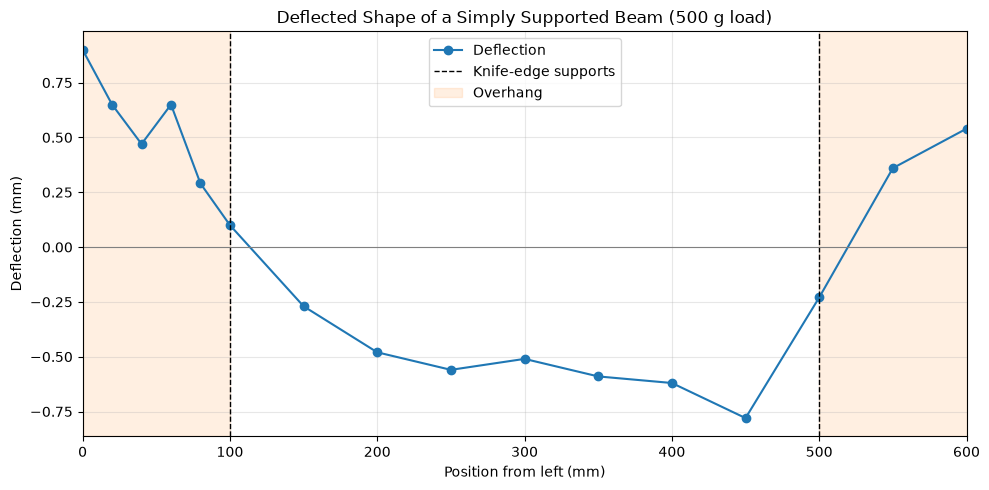

In [20]:
#experiment 3 for mechanics of structures
import matplotlib.pyplot as plt

position = [0, 20, 40, 60, 80, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600]
datum    = [0, -0.09, -0.14, -0.05, 0.03, -0.12, -0.38, -0.57, -0.95, -1.35, -1.33, -1.43, -1.28, -1.48, -1.73, -1.85]
loaded   = [0.9, 0.56, 0.33, 0.6, 0.32, -0.02, -0.65, -1.05, -1.51, -1.86, -1.92, -2.05, -2.06, -1.71, -1.37, -1.31]

# True deflection = loaded reading - datum reading
deflection = [l - d for l, d in zip(loaded, datum)]

# Supports are 200 mm either side of the beam centre (300 mm)
centre = 300
left_support = centre - 200   # 100 mm
right_support = centre + 200  # 500 mm

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(position, deflection, "o-", color="tab:blue", label="Deflection")

# Mark supports and shade the overhanging regions
ax.axvline(left_support, color="k", linestyle="--", linewidth=1, label="Knife-edge supports")
ax.axvline(right_support, color="k", linestyle="--", linewidth=1)
ax.axvspan(0, left_support, color="tab:orange", alpha=0.12, label="Overhang")
ax.axvspan(right_support, 600, color="tab:orange", alpha=0.12)
ax.axhline(0, color="grey", linewidth=0.8)

ax.set_xlabel("Position from left (mm)")
ax.set_ylabel("Deflection (mm)")
ax.set_title("Deflected Shape of a Simply Supported Beam (500 g load)")
ax.set_xlim(0, 600)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("beam_shape.png", dpi=300)
plt.show()

Gradient (E) = 2.050e+11 N/m^2 (205.0 GPa)
Intercept    = -1.400e+01
R^2          = 1.00000


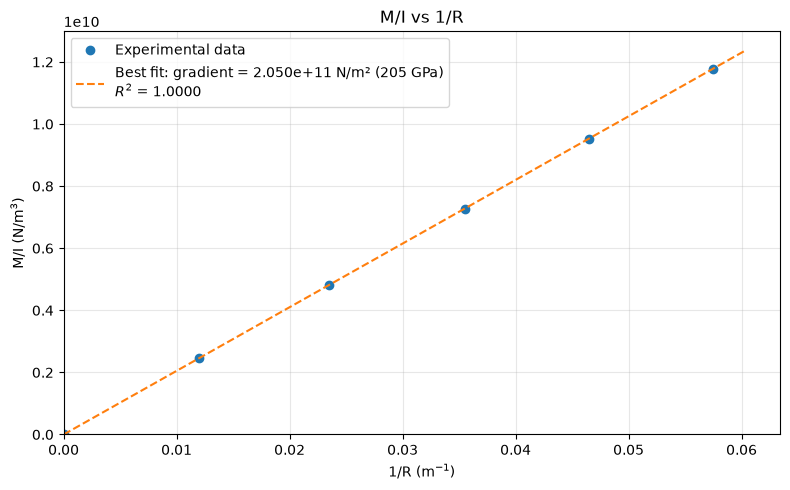

In [15]:
#experiment 4 for mechanics of structures 
import numpy as np
import matplotlib.pyplot as plt

inv_R = np.array([0, 0.01200048, 0.023501763, 0.035498758, 0.046490005, 0.057504313])  # m^-1
M_over_I = np.array([0, 2460098404, 4817861340, 7277245296, 9530450953, 11788384129])  # N/m^3

# Linear fit: M/I = E * (1/R) + c
gradient, intercept = np.polyfit(inv_R, M_over_I, 1)

# R^2
fit = gradient * inv_R + intercept
ss_res = np.sum((M_over_I - fit) ** 2)
ss_tot = np.sum((M_over_I - np.mean(M_over_I)) ** 2)
r_squared = 1 - ss_res / ss_tot

print(f"Gradient (E) = {gradient:.3e} N/m^2 ({gradient / 1e9:.1f} GPa)")
print(f"Intercept    = {intercept:.3e}")
print(f"R^2          = {r_squared:.5f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(inv_R, M_over_I, "o", label="Experimental data")

x_line = np.linspace(0, inv_R.max() * 1.05, 100)
ax.plot(x_line, gradient * x_line + intercept, "--",
        label=f"Best fit: gradient = {gradient:.3e} N/m² ({gradient / 1e9:.0f} GPa)\n$R^2$ = {r_squared:.4f}")

ax.set_xlabel("1/R (m$^{-1}$)")
ax.set_ylabel("M/I (N/m$^3$)")
ax.set_title("M/I vs 1/R")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("bending_plot.png", dpi=300)
plt.show()